# 01 · Preprocessing — malignant cell-state manifold (cutaneous SCC, Ji et al. 2020)

Isolate malignant cells, drop under-populated samples (data-driven multiplicative-gap
threshold), integrate patients with Harmony (integration strength chosen from a mixing
sweep, read off the **embedding**), embed, remove detached islands by connected components,
and cluster. Cutaneous squamous-cell carcinoma is a keratinocyte malignancy whose malignant
compartment spans a **differentiating** body, a **basal / tumour-specific-keratinocyte
(TSK)** leading edge, and a prominent **cycling** compartment. Every tunable choice is
*derived from this dataset* (not inherited from the Puram anchor) and *shown* in the
notebook. Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:

import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors, radius_neighbors_graph
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

name = os.path.basename(os.getcwd())                    # Ji2020_Skin-1 (attempt dir)
import re; dset = re.sub(r'-\d+$', '', name)            # strip -N attempt suffix -> input key
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                     # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name) # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)


dataset: Ji2020_Skin-1 | category: Skin


Ji et al. distribute a malignant-cell atlas of 10 cSCC patients with published malignant
subtype calls in `cell_subtype_level1` (Keratinocyte, Tumor_KC_Diff, Tumor_KC_Basal,
Tumor_KC_Cyc, and **TSK**). The loader normalizes 10x UMI counts and sets
`celltype='Malignant'` for these cells; we take the publication's malignant calls directly
(per protocol §3).

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full load:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('published subtypes (cell_subtype_level1):', adata.obs['cell_subtype_level1'].value_counts().to_dict())
print('cell-cycle phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalized 10x counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.
full load: (48164, 32738)
malignant: (10598, 32738) | samples: 10
published subtypes (cell_subtype_level1): {'Keratinocyte': 5715, 'Tumor_KC_Diff': 2370, 'Tumor_KC_Basal': 1395, 'Tumor_KC_Cyc': 794, 'TSK': 324}
cell-cycle phase: {'Not cycling': 6836, 'G1/S': 1678, 'G2/M': 1504, 'Intermediate': 560}
expression: X max 8.12 (log1p of normalized 10x counts)


### Sample threshold — data-driven multiplicative gap
Per-sample malignant counts span two orders of magnitude. Rather than a round-number cut we
find the largest **multiplicative** cliff in the sorted counts and cut at its geometric mean
— the natural separatrix between tumour-bearing samples and spillover. Two patients (P3, P5)
contribute only a few dozen malignant cells and fall below the cliff.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
FLOOR = 100
thresh = FLOOR if gap == 0 else int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: {'P4': np.int64(4216), 'P8': np.int64(1472), 'P10': np.int64(1130), 'P1': np.int64(1064), 'P7': np.int64(1012), 'P6': np.int64(729), 'P2': np.int64(640), 'P9': np.int64(268), 'P5': np.int64(40), 'P3': np.int64(27)}
largest multiplicative gap: 268 -> 40 (ratio 6.70)
derived threshold (geometric mean across the gap) = 103
kept 8/10 samples -> 10531 cells


### Genes, overdispersion, PCA

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 1443


### Integration strength — same-sample-neighbour sweep, judged on the embedding
cSCC malignant cells carry strong patient-specific CNVs, so integration must be strong enough
to mix patients without collapsing biological structure. Per the binding Gate-1 lesson
(Kürten §1) the choice is made **on the regenerated embedding across an integration sweep**,
not on a scalar alone. We sweep Harmony `theta`, record the same-sample neighbour fraction
(lower = better mixing) **and re-embed at each theta** to inspect patient mixing directly. The
scalar declines monotonically (no sharp knee), so the embedding is the arbiter: at `theta=0`
patient P4/P8 own distinct lobes; by `theta=5` no patient owns a region and the manifold reads
as one integrated continuum, with only cosmetic change to `theta=10`. We adopt **theta=5** —
the point of clean visual mixing, matching the 10x precedents (Kürten `theta=10`, comparable
cell count). Crucially the downstream signature geography (02) is verified **invariant across
theta 1–10** (Gast/pSom overlap, both oppose Crest), so the geometry verdict does not depend on
this choice. `n_pcs=20`, UMAP `spread=1.3` follow the 10x precedents, not the Puram anchor.

In [ ]:
def same_sample_frac(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
NPC = 20
base = same_sample_frac(adata.obsm['X_pca'][:, :NPC])
sweep = {}
reps = {}
for th in [0, 1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    reps[th] = adata.obsm['X_pca_harmony'].copy()
    sweep[th] = same_sample_frac(adata.obsm['X_pca_harmony'][:, :NPC])
print('pre-Harmony same-sample neighbour fraction: %.3f' % base)
print('theta sweep (same-sample frac):', {k: round(v,3) for k,v in sweep.items()},
      '(monotone decline, no knee -> arbitrate on the embedding below)')

pre-Harmony same-sample neighbour fraction: 0.851
theta sweep (same-sample frac): {0: 0.494, 1: 0.374, 2: 0.365, 5: 0.351, 10: 0.344} (monotone decline, no knee -> arbitrate on the embedding below)


#### Sweep the embedding — sample mixing at each theta (Gate-1 diagnostic)
Re-embed at theta = 0 / 2 / 5 / 10 and colour by patient. This is the binding standard: Gate 1
is read off the embedding across the integration sweep, not a scalar. theta=0 shows patient-owned
lobes (P4 green, P8 brown); mixing is visually clean by theta=5.

adopted theta=5


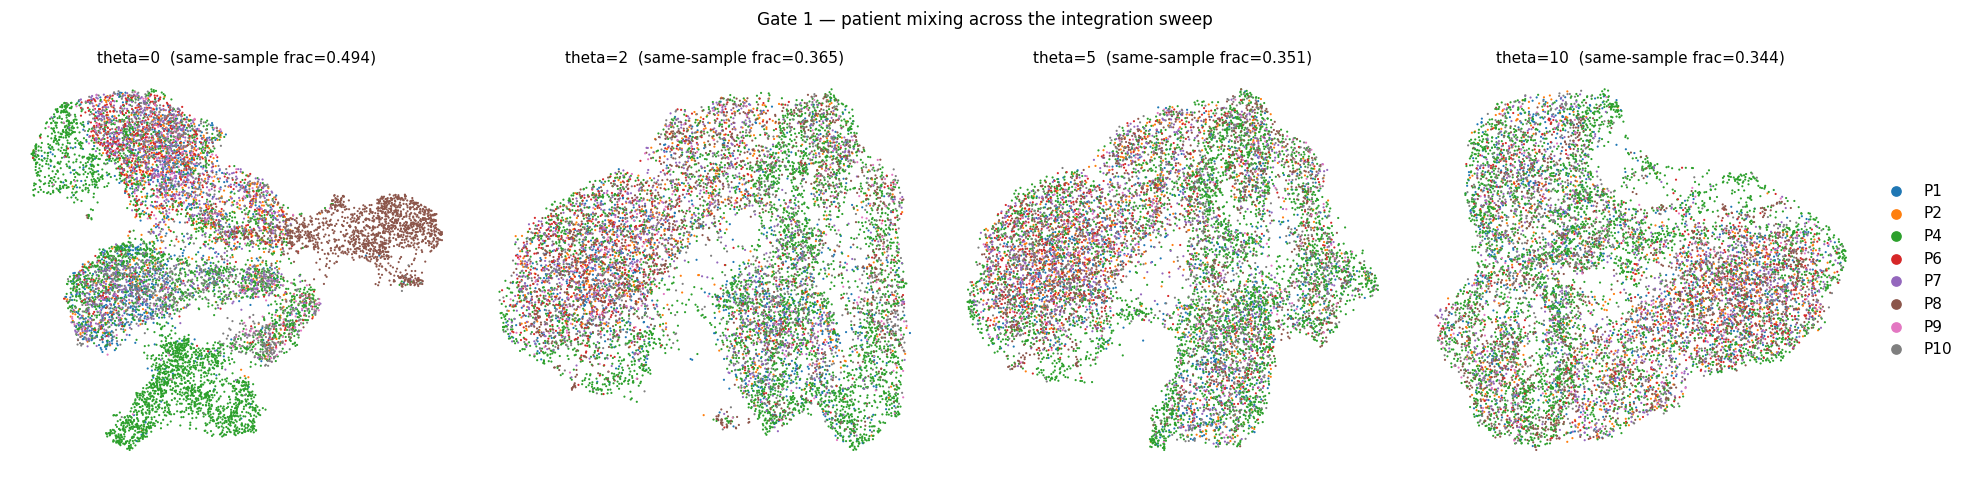

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, th in zip(axs, [0, 2, 5, 10]):
    tmp = adata.copy(); tmp.obsm['X_pca_harmony'] = reps[th]
    sc.pp.neighbors(tmp, n_pcs=NPC, use_rep='X_pca_harmony', random_state=SEED)
    sc.tl.umap(tmp, spread=1.3, random_state=SEED)
    sc.pl.umap(tmp, color='sample', ax=ax, show=False, size=8, frameon=False,
               legend_loc='right margin' if th == 10 else None)
    ax.set_title(f'theta={th}  (same-sample frac={sweep[th]:.3f})', size=10)
fig.suptitle('Gate 1 — patient mixing across the integration sweep', size=11)
fig.tight_layout()
# adopt theta=5 (clean visual mixing, 10x precedent; geometry verdict theta-invariant per 02)
sce.pp.harmony_integrate(adata, 'sample', theta=5, max_iter_harmony=30, random_state=SEED)
print('adopted theta=5')

### Embed and cluster

leiden clusters: 14


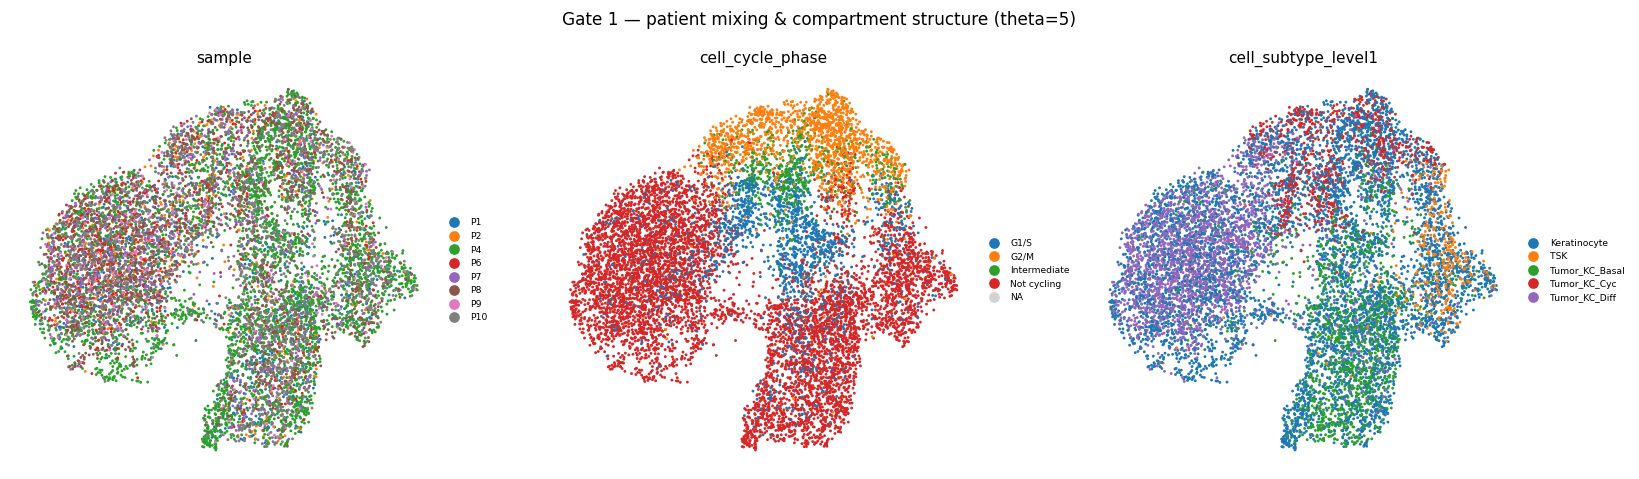

In [ ]:
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
sc.tl.leiden(adata, resolution=1.0, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
print('leiden clusters:', adata.obs.leiden.nunique())
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, c in zip(axs, ['sample', 'cell_cycle_phase', 'cell_subtype_level1']):
    ll = 'right margin'
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=14, frameon=False, legend_loc=ll, legend_fontsize=6)
    ax.set_title(c, size=10)
fig.suptitle('Gate 1 — patient mixing & compartment structure (theta=5)', size=11)
fig.tight_layout()

**Gate 1 (mixing) — GO on the embedding.** Patients are thoroughly interspersed across the
manifold (no per-patient archipelago); the sweep above shows mixing is visually clean by theta=5.
The cell-cycle panel shows a distinct **cycling compartment** (G2/M + G1/S) — carried forward
and examined in 02, since neural-crest signature geography overlaps it.

### Island removal — connected components on a UMAP radius graph
Build a radius graph at 6× the median nearest-neighbour distance, take connected components,
keep the largest. This strips only genuinely detached specks (conservative, derived — no
hand-listed clusters).

In [ ]:
xy = adata.obsm['X_umap']
d1 = NearestNeighbors(n_neighbors=2).fit(xy).kneighbors(xy)[0][:,1]
G = radius_neighbors_graph(xy, 6*np.median(d1), mode='connectivity')
ncomp, lab = connected_components(G, directed=False)
sizes = pd.Series(lab).value_counts()
keep_lab = sizes.index[0]
print(f'radius-graph components: {ncomp}; top sizes {sizes.head(4).tolist()}')
print(f'largest component = {sizes.iloc[0]}/{adata.n_obs} ({100*sizes.iloc[0]/adata.n_obs:.1f}%)')
adata = adata[lab == keep_lab].copy()
print('after island removal:', adata.n_obs, 'cells (continuous single component -> Gate 1 continuity GO)')

radius-graph components: 18; top sizes [10504, 3, 3, 3]
largest component = 10504/10531 (99.7%)
after island removal: 10504 cells (continuous single component -> Gate 1 continuity GO)


### Annotate subtypes — publication calls + data-derived hub
Annotation uses **both** the publication's `cell_subtype_level1` calls and data-derived module
geography (protocol §3). Published calls map to compact labels; the low-cycling clusters with
the highest joint gastrulation+somitogenesis score are relabelled **Mixed** — the developmental
convergence core (the Gast/pSom-overlap zone), identified by role, not by name. High-cycling
clusters are labelled **Cycling**.

hub (Mixed) clusters: ['6', '2'] | Cycling clusters: ['0', '4', '8', '9', '13']
celltype counts: {'Cycling': 3452, 'KC': 2808, 'Mixed': 1787, 'Diff': 1162, 'Basal': 1073, 'TSK': 222}


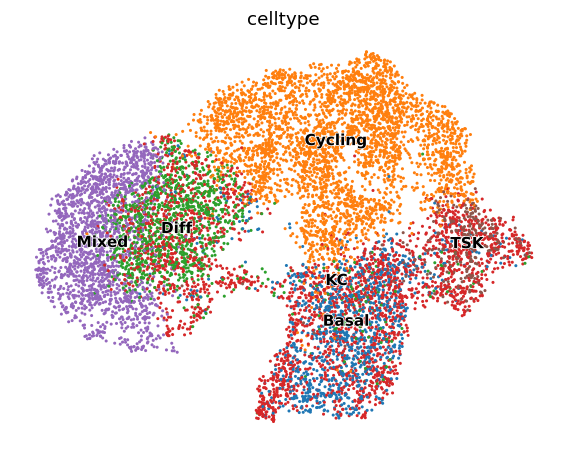

In [ ]:
# score modules quickly for annotation (full scoring in 02)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l_ in enumerate(['Gast','pSom','Crest']): adata.obs[l_+'_sm'] = S[:,j]
adata.obs['cyc_frac'] = (adata.obs.cell_cycle_phase != 'Not cycling').astype(float)

cl = adata.obs.groupby('leiden', observed=True).agg(
    Gast=('Gast_sm','mean'), pSom=('pSom_sm','mean'), cyc=('cyc_frac','mean'))
cl['gp'] = cl.Gast.rank(pct=True) + cl.pSom.rank(pct=True)
sub_map = {'Tumor_KC_Diff':'Diff','Tumor_KC_Basal':'Basal','TSK':'TSK','Tumor_KC_Cyc':'Cycling','Keratinocyte':'KC'}
adata.obs['celltype'] = adata.obs.cell_subtype_level1.map(sub_map).astype('object')
hub_cls = cl[cl.cyc < 0.2].sort_values('gp', ascending=False).head(2).index.tolist()
cyc_cls = cl[cl.cyc > 0.6].index.tolist()
adata.obs.loc[adata.obs.leiden.isin(hub_cls), 'celltype'] = 'Mixed'
adata.obs.loc[adata.obs.leiden.isin(cyc_cls), 'celltype'] = 'Cycling'
adata.obs['celltype'] = adata.obs['celltype'].astype('category')
print('hub (Mixed) clusters:', hub_cls, '| Cycling clusters:', cyc_cls)
print('celltype counts:', adata.obs.celltype.value_counts().to_dict())
sc.pl.umap(adata, color='celltype', size=16, frameon=False, legend_loc='on data', legend_fontoutline=1)

### Save processed data + sample figure (deliverable)

saved processed.h5ad + samples.pdf | 10504 cells


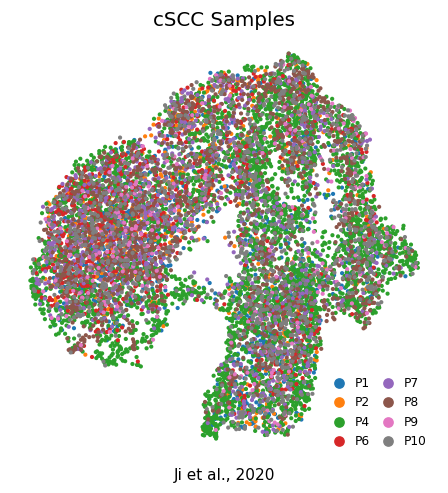

In [ ]:
# drop bulky smoothed/temp cols kept only for annotation; recomputed cleanly in 02
adata.write(os.path.join(pth_out, 'processed.h5ad'))
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=30, frameon=False, show=False, ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('cSCC Samples', size=13)
ax.text(.5, -.05, 'Ji et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved processed.h5ad + samples.pdf |', adata.n_obs, 'cells')